# Deep Learning Project – Flower classification with CNNs and Transfer Learning

**Team :** Member 1, Member 2, Member 3


**Goal :** classify photos of flowers into 5 categories (daisy, dandelion, roses, sunflowers, tulips).

We compare :

* a simple CNN trained from scratch (baseline)
* an improved CNN (data augmentation, batch normalization, dropout)
* transfer learning with **MobileNetV2** pretrained on ImageNet : feature extraction, then fine-tuning
* an extra experiment : a second pretrained backbone (**EfficientNetB0**)

At the end we look at the errors (confusion matrix) and we use **Grad-CAM** to see where the model is looking.


> Run it on Google Colab with a GPU (Runtime > Change runtime type > GPU), the whole notebook takes around 15 min.

## 0. Setup

In [1]:
import sys, platform
print(sys.version)
print(platform.system(), platform.machine())

3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Linux x86_64


In [2]:
import os
import pathlib

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import tensorflow as tf
import keras
from keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay


print("TensorFlow :", tf.__version__)
print("Keras :", keras.__version__)
print("GPU :", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.21.0
Keras : 3.13.2
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# same seed everywhere so the runs are (almost) reproducible
SEED = 42
keras.utils.set_random_seed(SEED)

IMG_SIZE   = 160
BATCH_SIZE = 32

# number of epochs for each experiment (early stopping will often stop before)
EPOCHS_SCRATCH  = 30
EPOCHS_IMPROVED = 50
EPOCHS_TL       = 15
EPOCHS_FINETUNE = 10

## 1. Dataset

We use the **TensorFlow Flowers** dataset : 3,670 photos of flowers, split in 5 folders (one folder per class).

The photos come from Flickr, they have different sizes, and the background, the light and the framing change a lot from one image to another. It's a small dataset for a CNN, so it's a good case to show the interest of transfer learning.

In [4]:
URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

archive = keras.utils.get_file("flower_photos", origin=URL, untar=True)
data_dir = pathlib.Path(archive)

# depending on the keras version the images can be one folder deeper
if not (data_dir / "daisy").exists():
    data_dir = data_dir / "flower_photos"

print(data_dir)

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
/root/.keras/datasets/flower_photos/flower_photos


In [5]:
class_names = sorted([d.name for d in data_dir.iterdir() if d.is_dir()])
num_classes = len(class_names)

print("Classes :", class_names)


paths, labels = [], []

for i, name in enumerate(class_names):
    files = sorted((data_dir / name).glob("*.jpg"))
    paths  += [str(f) for f in files]
    labels += [i] * len(files)

paths  = np.array(paths)
labels = np.array(labels)

print("Total images :", len(paths))

Classes : ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Total images : 3670


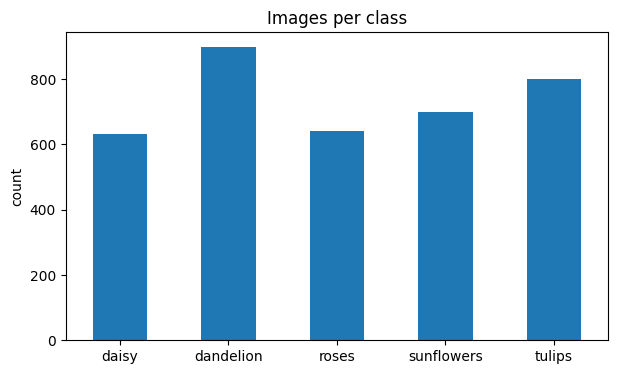

daisy         633
dandelion     898
roses         641
sunflowers    699
tulips        799
Name: count, dtype: int64


In [6]:
# number of images per class
counts = pd.Series(labels).value_counts().sort_index()
counts.index = class_names

counts.plot(kind="bar", figsize=(7, 4), title="Images per class")
plt.ylabel("count")
plt.xticks(rotation=0)
plt.show()

print(counts)

The classes are not perfectly balanced (dandelion has the most images, roses the fewest) but the difference is small, so accuracy stays a meaningful metric. We will still look at the per-class results at the end.

### Train / validation / test split

70 % train, 15 % validation, 15 % test.

The split is **stratified** so each class keeps the same proportion in the 3 sets. The test set is only used at the very end, to compare the final models. Everything else (early stopping, choices of hyperparameters) is done with the validation set.

In [7]:
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=SEED
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.50, stratify=temp_labels, random_state=SEED
)


print("Train :", len(train_paths))
print("Val   :", len(val_paths))
print("Test  :", len(test_paths))

Train : 2569
Val   : 550
Test  : 551


### tf.data pipeline

Each image is read, decoded and resized to 160x160. We keep the pixels in [0, 255] here, the scaling is done **inside** each model (because the pretrained networks expect their own preprocessing).

`cache()` keeps the decoded images in memory after the first epoch (stored as uint8 to save RAM), and `prefetch()` prepares the next batch while the GPU is working on the current one.

In [8]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.uint8)
    return img, label


def make_dataset(paths, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.cache()

    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED)

    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y))
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = make_dataset(train_paths, train_labels, shuffle=True)
val_ds   = make_dataset(val_paths, val_labels)
test_ds  = make_dataset(test_paths, test_labels)   # not shuffled -> same order as test_labels

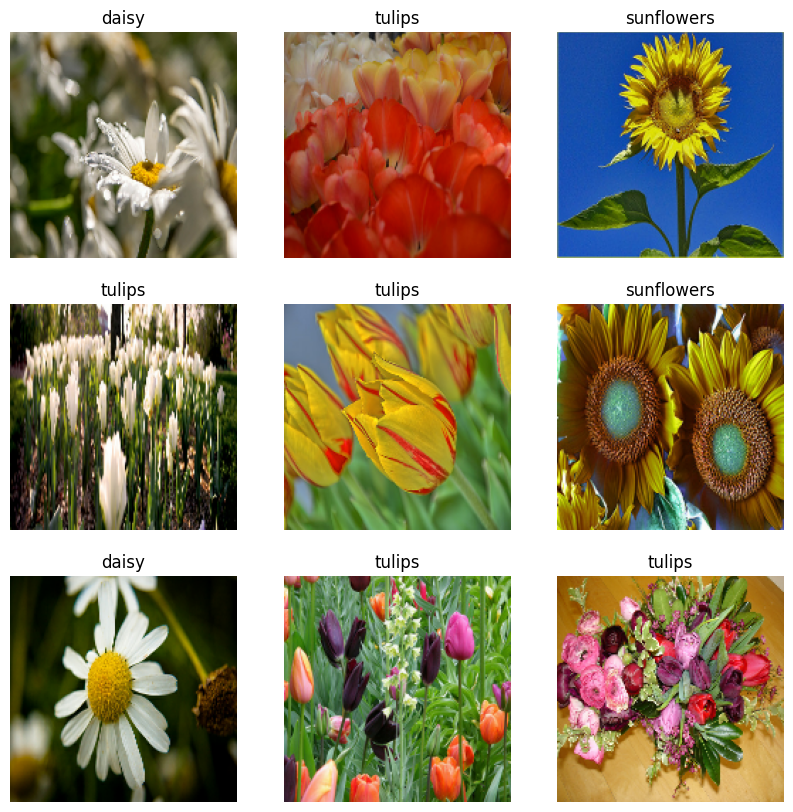

Batch shape : (32, 160, 160, 3)


In [9]:
# a few examples from the training set
images, lbls = next(iter(train_ds))

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[lbls[i]])
    plt.axis("off")
plt.show()

print("Batch shape :", images.shape)

## 2. Helper functions

Small functions we reuse for every model : training with early stopping, plotting the curves, and storing the test results.

In [10]:
results = {}     # name -> test accuracy
histories = {}   # name -> keras history


def train(model, name, epochs, patience=5, initial_epoch=0):
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=patience,
        restore_best_weights=True,
        verbose=1
    )

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        initial_epoch=initial_epoch,
        callbacks=[early_stop]
    )
    histories[name] = history
    return history


def plot_history(history, title):
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(epochs, h["accuracy"], "o-", label="train")
    axes[0].plot(epochs, h["val_accuracy"], "s-", label="validation")
    axes[0].set_title(title + " - accuracy")

    axes[1].plot(epochs, h["loss"], "o-", label="train")
    axes[1].plot(epochs, h["val_loss"], "s-", label="validation")
    axes[1].set_title(title + " - loss")

    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
        ax.legend()

    plt.tight_layout()
    plt.show()


def evaluate(model, name):
    loss, acc = model.evaluate(test_ds, verbose=0)
    results[name] = acc
    print(f"{name}  ->  test loss = {loss:.4f}   test accuracy = {acc:.2%}")

## 3. Baseline : CNN from scratch

A classic architecture : 3 blocks **Conv2D + ReLU + MaxPooling**, with 32, 64 then 128 filters, then a dense classifier.

* the convolutions learn local patterns (edges, colors, textures, then petal shapes)
* max pooling divides the spatial size by 2 each time, so the deeper filters see a bigger part of the image
* the last layer is a softmax over the 5 classes

The labels are integers (0 to 4), so we use `sparse_categorical_crossentropy`.

In [11]:
def build_baseline():
    model = keras.Sequential([
        keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.Rescaling(1. / 255),

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(num_classes, activation="softmax")
    ], name="baseline_cnn")

    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


baseline = build_baseline()
baseline.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,621 (25.36 MB)

 Trainable params: 6,647,621 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

Most of the parameters are in the first Dense layer : the Flatten gives 20 x 20 x 128 = 51,200 values, connected to 128 neurons. That's a lot of parameters for only ~2,500 training images, so we expect overfitting.

In [12]:
history_baseline = train(baseline, "Baseline CNN", EPOCHS_SCRATCH, patience=5)

Epoch 1/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 186ms/step - accuracy: 0.4691 - loss: 1.2352 - val_accuracy: 0.5927 - val_loss: 1.0339
Epoch 2/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.6349 - loss: 0.9378 - val_accuracy: 0.6382 - val_loss: 0.9174
Epoch 3/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.7232 - loss: 0.7304 - val_accuracy: 0.6745 - val_loss: 0.8601
Epoch 4/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.7976 - loss: 0.5368 - val_accuracy: 0.6745 - val_loss: 0.8867
Epoch 5/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.8735 - loss: 0.3485 - val_accuracy: 0.6655 - val_loss: 1.0152
Epoch 6/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9194 - loss: 0.2388 - val_accuracy: 0.6564 - val_loss: 1.0730
Epoch 7/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.9661 - loss: 0.1220 - val_accuracy: 0.6509 - val_loss: 1.2653
Epoch 8/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9852 - loss: 0.0622 - val_accuracy: 0.6655 -

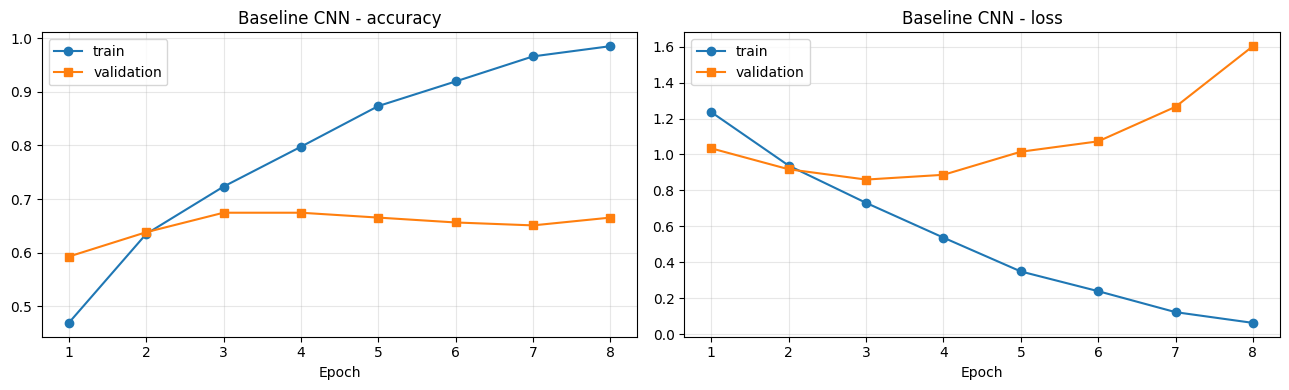

Baseline CNN  ->  test loss = 0.8621   test accuracy = 66.61%


In [13]:
plot_history(history_baseline, "Baseline CNN")
evaluate(baseline, "Baseline CNN")

**Observation.** The training accuracy keeps going up quickly while the validation accuracy stops improving after a few epochs and the validation loss goes back up : the model **overfits**, it memorizes the training images instead of learning general features. Early stopping gives us back the weights of the best epoch, but the gap between train and validation stays large.

## 4. Improved CNN

Same idea but with the regularization techniques we saw in Lab 3 :

* **data augmentation** : random flips, rotations, zooms and contrast changes. These layers are only active during training. A flower stays the same flower if the photo is flipped or slightly rotated, so it creates "new" training examples for free.
* **batch normalization** after each convolution : stabilizes training and allows a faster convergence
* **GlobalAveragePooling** instead of Flatten : each feature map becomes one number, so much fewer parameters in the classifier
* **dropout (0.5)** before the last layer

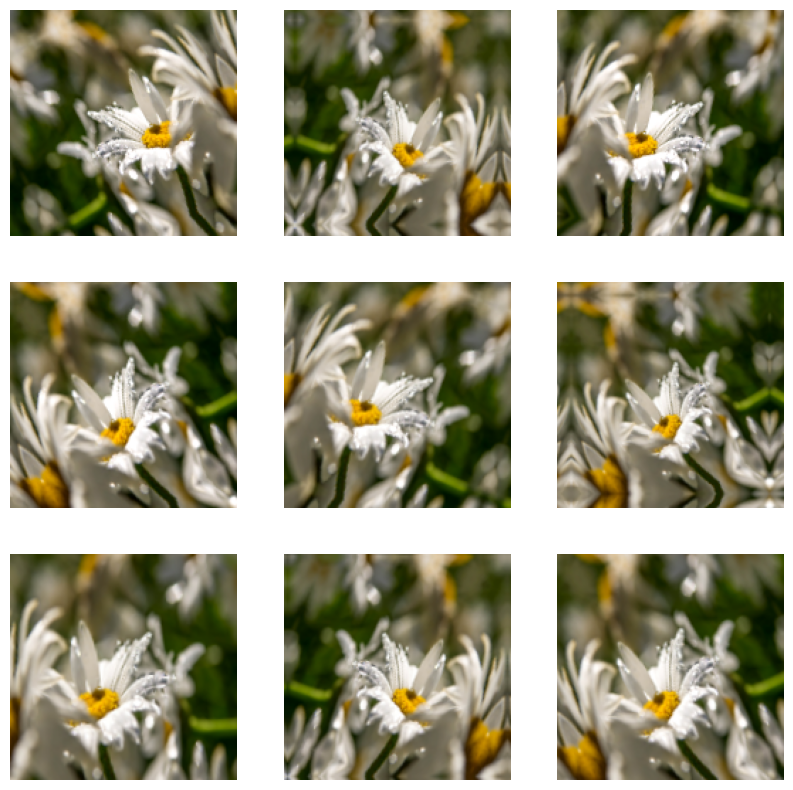

In [14]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="data_augmentation")


# what one image looks like after augmentation
img = images[0:1]

plt.figure(figsize=(10, 10))
for i in range(9):
    aug = data_augmentation(img, training=True)
    plt.subplot(3, 3, i + 1)
    plt.imshow(np.clip(aug[0].numpy(), 0, 255).astype("uint8"))
    plt.axis("off")
plt.show()

In [15]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.MaxPooling2D()(x)
    return x


def build_improved():
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = data_augmentation(inputs)
    x = layers.Rescaling(1. / 255)(x)

    for filters in [32, 64, 128, 256]:
        x = conv_block(x, filters)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="improved_cnn")
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


improved = build_improved()
improved.summary()

Model: "improved_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 160, 160, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 160, 160, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 80, 80, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 80, 80, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 40, 40, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 40, 40, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,176,421 (4.49 MB)

 Trainable params: 1,174,501 (4.48 MB)

 Non-trainable params: 1,920 (7.50 KB)

The convolutions use `use_bias=False` because the BatchNormalization just after already has its own shift parameter (beta), a bias would be useless.

In [16]:
history_improved = train(improved, "Improved CNN", EPOCHS_IMPROVED, patience=8)

Epoch 1/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 193ms/step - accuracy: 0.5029 - loss: 1.3014 - val_accuracy: 0.2436 - val_loss: 3.0906
Epoch 2/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 162ms/step - accuracy: 0.5605 - loss: 1.1525 - val_accuracy: 0.2418 - val_loss: 2.3226
Epoch 3/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 167ms/step - accuracy: 0.5979 - loss: 1.0314 - val_accuracy: 0.2491 - val_loss: 3.0429
Epoch 4/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 162ms/step - accuracy: 0.6119 - loss: 1.0172 - val_accuracy: 0.5055 - val_loss: 1.4114
Epoch 5/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 158ms/step - accuracy: 0.6372 - loss: 0.9551 - val_accuracy: 0.4836 - val_loss: 1.2807
Epoch 6/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 157ms/step - accuracy: 0.6368 - loss: 0.9221 - val_accuracy: 0.5400 - val_loss: 1.1501
Epoch 7/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 158ms/step - accuracy: 0.6485 - loss: 0.8974 - val_accuracy: 0.5364 - val_loss: 1.4122
Epoch 8/50
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 159ms/step - accuracy: 0.6734 - loss: 0.8613 - val_accu

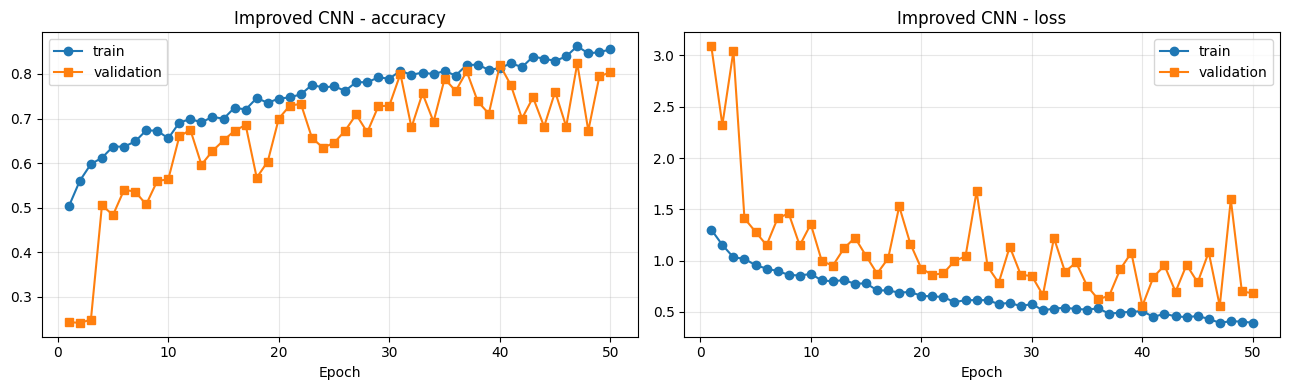

Improved CNN  ->  test loss = 0.6098   test accuracy = 81.31%


In [17]:
plot_history(history_improved, "Improved CNN")
evaluate(improved, "Improved CNN")

**Observation.** The train and validation curves stay much closer : the augmentation makes the training task harder, so the model can't simply memorize. The validation curve is noisier (batch norm + a small validation set) but it keeps improving for more epochs, and the test accuracy is better than the baseline.

Still, with ~2,500 images it's hard to learn good visual features from zero. That's where transfer learning helps.

## 5. Transfer learning : MobileNetV2

**Idea :** a network trained on ImageNet (1.2 million images, 1000 classes) has already learned generic visual features : edges and colors in the first layers, textures and object parts in the deeper ones. We reuse these features and only train a new classifier for our 5 classes.

We choose **MobileNetV2** : light (~2.3 M parameters in the base), fast, and good on ImageNet. It uses depthwise separable convolutions and inverted residual blocks.

Two steps :

1. **Feature extraction** : the base is frozen, we only train the new head
2. **Fine-tuning** : we unfreeze the last layers of the base and train them with a very small learning rate

In [18]:
base_model = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,          # we remove the ImageNet classifier
    weights="imagenet"
)

base_model.trainable = False   # freeze all the convolutional layers

print("Layers in the base model :", len(base_model.layers))
print("Output shape :", base_model.output_shape)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Layers in the base model : 154
Output shape : (None, 5, 5, 1280)


MobileNetV2 expects pixels in [-1, 1], so we use its own `preprocess_input` function.

We call the base with `training=False` : this keeps the BatchNormalization layers in inference mode (they use the ImageNet statistics). It's important for the fine-tuning later, otherwise the batch norm statistics would be updated with our small batches and destroy what the network learned.

In [19]:
preprocess = keras.applications.mobilenet_v2.preprocess_input


def build_transfer(base, preprocess_fn, name):
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = data_augmentation(inputs)
    x = preprocess_fn(x)
    x = base(x, training=False)

    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.2, name="head_dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)

    model = keras.Model(inputs, outputs, name=name)
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


tl_model = build_transfer(base_model, preprocess, "mobilenetv2_tl")
tl_model.summary()

Model: "mobilenetv2_tl"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Only the last Dense layer is trainable : 1280 x 5 + 5 = 6,405 parameters, compared to millions in the frozen base.

In [20]:
history_tl = train(tl_model, "MobileNetV2 - feature extraction", EPOCHS_TL, patience=4)

Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 80ms/step - accuracy: 0.6434 - loss: 0.9279 - val_accuracy: 0.8109 - val_loss: 0.5058
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.8268 - loss: 0.4934 - val_accuracy: 0.8327 - val_loss: 0.4430
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.8529 - loss: 0.4004 - val_accuracy: 0.8509 - val_loss: 0.3997
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.8587 - loss: 0.3711 - val_accuracy: 0.8709 - val_loss: 0.3819
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.8774 - loss: 0.3251 - val_accuracy: 0.8600 - val_loss: 0.3872
Epoch 6/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.8937 - loss: 0.2953 - val_accuracy: 0.8727 - val_loss: 0.3813
Epoch 7/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.8918 - loss: 0.2902 - val_accuracy: 0.8709 - val_loss: 0.3705
Epoch 8/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.8984 - loss: 0.2710 - val_accuracy: 0.8691 - 

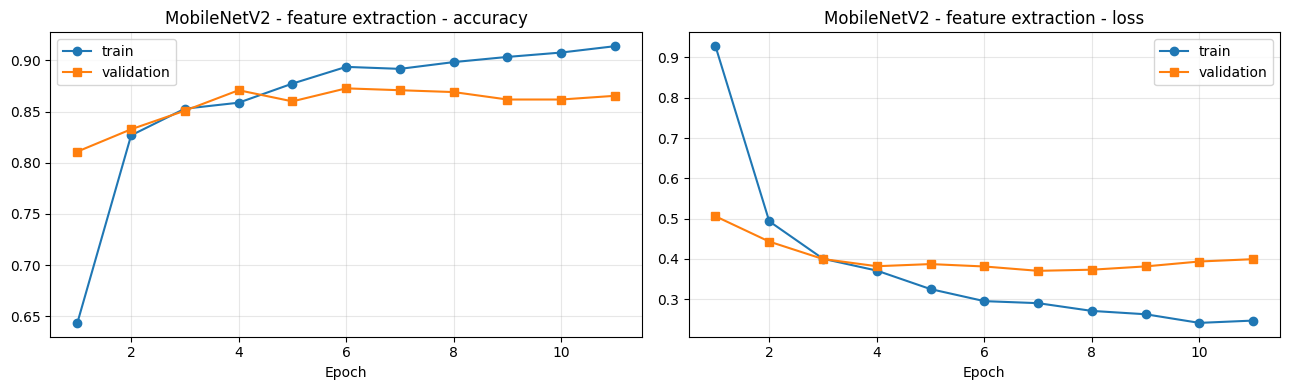

MobileNetV2 - feature extraction  ->  test loss = 0.3137   test accuracy = 88.38%


In [21]:
plot_history(history_tl, "MobileNetV2 - feature extraction")
evaluate(tl_model, "MobileNetV2 - feature extraction")

**Observation.** Already after the first epoch the validation accuracy is above what the CNNs trained from scratch reach at the end. The pretrained features are very well suited to natural images like flowers.

(The validation accuracy can even be above the train accuracy here : dropout and data augmentation are only active during training, which makes the training task harder.)

### Fine-tuning

Now we unfreeze the **top layers** of MobileNetV2 (from layer 100 to the end). The first layers detect very generic things (edges, colors) so we keep them frozen, the last ones are more specific to ImageNet objects, so it makes sense to adapt them to flowers.

The learning rate is divided by 100 (1e-5) : the weights are already good, we only want to adjust them a little. A big learning rate would destroy the pretrained features at the start of the fine-tuning, when the gradients are still large.

We have to **compile again** after changing `trainable`, otherwise the change is not taken into account.

In [22]:
base_model.trainable = True

fine_tune_at = 100
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False


n_trainable = sum(l.trainable for l in base_model.layers)
print(f"Trainable layers in the base : {n_trainable} / {len(base_model.layers)}")


tl_model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Trainable layers in the base : 54 / 154


In [23]:
start = len(history_tl.history["loss"])

history_ft = train(
    tl_model,
    "MobileNetV2 - fine-tuning",
    epochs=start + EPOCHS_FINETUNE,
    initial_epoch=start,
    patience=4
)

Epoch 12/21
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 89ms/step - accuracy: 0.7960 - loss: 0.5523 - val_accuracy: 0.8709 - val_loss: 0.3669
Epoch 13/21
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 63ms/step - accuracy: 0.8377 - loss: 0.4397 - val_accuracy: 0.8764 - val_loss: 0.3693
Epoch 14/21
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 68ms/step - accuracy: 0.8529 - loss: 0.3908 - val_accuracy: 0.8800 - val_loss: 0.3708
Epoch 15/21
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - accuracy: 0.8731 - loss: 0.3431 - val_accuracy: 0.8800 - val_loss: 0.3661
Epoch 16/21
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 66ms/step - accuracy: 0.8813 - loss: 0.3162 - val_accuracy: 0.8782 - val_loss: 0.3641
Epoch 17/21
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 70ms/step - accuracy: 0.8933 - loss: 0.3018 - val_accuracy: 0.8800 - val_loss: 0.3596
Epoch 18/21
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 67ms/step - accuracy: 0.8992 - loss: 0.2750 - val_accuracy: 0.8855 - val_loss: 0.3530
Epoch 19/21
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 67ms/step - accuracy: 0.9011 - loss: 0.2660 - val_accuracy: 

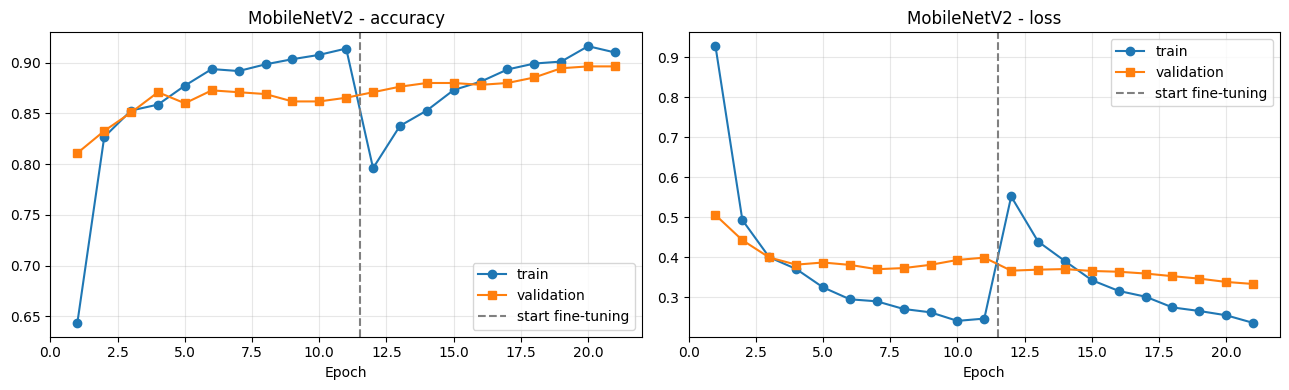

MobileNetV2 - fine-tuning  ->  test loss = 0.2555   test accuracy = 90.02%


In [24]:
# full curve : feature extraction + fine-tuning
acc      = history_tl.history["accuracy"] + history_ft.history["accuracy"]
val_acc  = history_tl.history["val_accuracy"] + history_ft.history["val_accuracy"]
loss     = history_tl.history["loss"] + history_ft.history["loss"]
val_loss = history_tl.history["val_loss"] + history_ft.history["val_loss"]

epochs = range(1, len(acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs, acc, "o-", label="train")
axes[0].plot(epochs, val_acc, "s-", label="validation")
axes[0].set_title("MobileNetV2 - accuracy")

axes[1].plot(epochs, loss, "o-", label="train")
axes[1].plot(epochs, val_loss, "s-", label="validation")
axes[1].set_title("MobileNetV2 - loss")

for ax in axes:
    ax.axvline(start + 0.5, color="gray", linestyle="--", label="start fine-tuning")
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


evaluate(tl_model, "MobileNetV2 - fine-tuning")

**Observation.** Fine-tuning gives an extra gain on top of feature extraction, but a smaller one : most of the work was already done by the frozen features. We see the training accuracy going up faster than the validation one after unfreezing, so we have to keep the number of epochs small (early stopping) because the model now has a lot more trainable parameters and can overfit again.

## 6. Extra experiment : another backbone (EfficientNetB0)

Is MobileNetV2 a good choice ? We try **EfficientNetB0** with the same protocol (frozen base + new head, same number of epochs).

EfficientNet scales the depth, the width and the input resolution of the network together. It is more accurate on ImageNet than MobileNetV2 but also a bit heavier (~4 M parameters in the base).

Note : in Keras, EfficientNet includes its own rescaling layer, so it takes the pixels directly in [0, 255], the `preprocess_input` function does nothing.

In [25]:
effnet_base = keras.applications.EfficientNetB0(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
effnet_base.trainable = False


effnet_model = build_transfer(
    effnet_base,
    keras.applications.efficientnet.preprocess_input,
    "efficientnetb0_tl"
)

history_effnet = train(effnet_model, "EfficientNetB0 - feature extraction", EPOCHS_TL, patience=4)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 109ms/step - accuracy: 0.6983 - loss: 0.8441 - val_accuracy: 0.8309 - val_loss: 0.5285
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - accuracy: 0.8369 - loss: 0.4936 - val_accuracy: 0.8564 - val_loss: 0.4328
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 55ms/step - accuracy: 0.8583 - loss: 0.4171 - val_accuracy: 0.8564 - val_loss: 0.3925
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 56ms/step - accuracy: 0.8750 - loss: 0.3605 - val_accuracy: 0.8745 - val_loss: 0.3608
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - accuracy: 0.8824 - loss: 0.3387 - val_accuracy: 0.8727 - val_loss: 0.3590
Epoch 6/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 55ms/step - accuracy: 0.8961 - loss: 0.3153 - val_accuracy: 0.8782 - val_loss: 0.3390
Epoch 7/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.8949 - loss: 0.2936 - val_accuracy: 0.8764 - val_loss: 0.3315
Epoch 8/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - accur

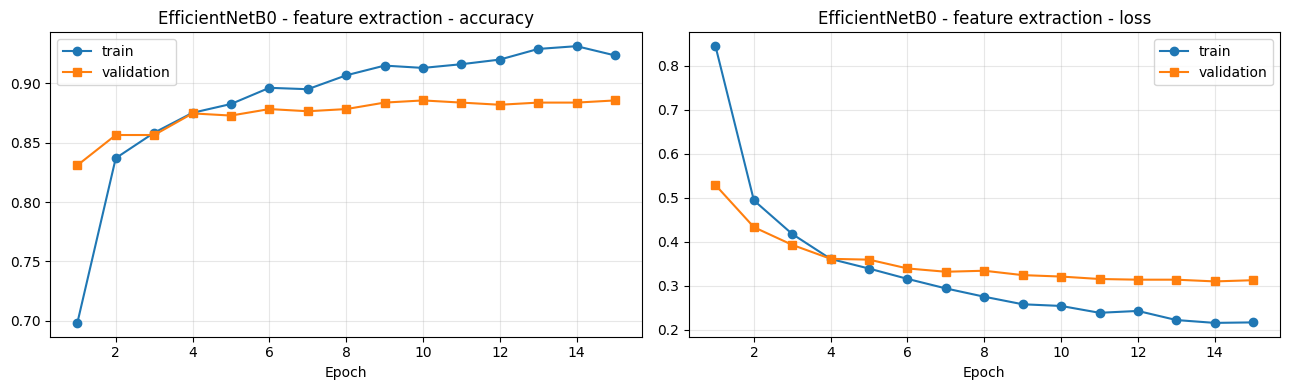

EfficientNetB0 - feature extraction  ->  test loss = 0.2675   test accuracy = 90.74%


In [26]:
plot_history(history_effnet, "EfficientNetB0 - feature extraction")
evaluate(effnet_model, "EfficientNetB0 - feature extraction")

In [27]:
# parameters of each model (total / trainable during the last training phase)
models_list = {
    "Baseline CNN": baseline,
    "Improved CNN": improved,
    "MobileNetV2 (fine-tuned)": tl_model,
    "EfficientNetB0 (frozen)": effnet_model,
}

rows = []
for name, m in models_list.items():
    trainable = int(sum(np.prod(w.shape) for w in m.trainable_weights))
    rows.append({"Model": name, "Total params": m.count_params(), "Trainable params": trainable})

pd.DataFrame(rows)

,Model,Total params,Trainable params
0,Baseline CNN,6647621,6647621
1,Improved CNN,1176421,1174501
2,MobileNetV2 (fine-tuned),2264389,1867845
3,EfficientNetB0 (frozen),4055976,6405


## 7. Comparison of all the models

                                 Model Test accuracy
1  EfficientNetB0 - feature extraction        90.74%
2            MobileNetV2 - fine-tuning        90.02%
3     MobileNetV2 - feature extraction        88.38%
4                         Improved CNN        81.31%
5                         Baseline CNN        66.61%


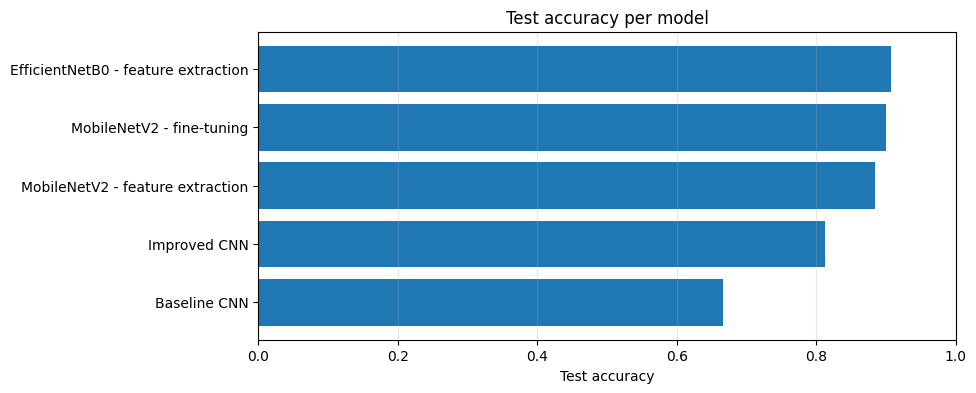

In [28]:
summary = (
    pd.DataFrame({"Model": list(results.keys()), "Test accuracy": list(results.values())})
    .sort_values("Test accuracy", ascending=False)
    .reset_index(drop=True)
)

summary.index = summary.index + 1
print(summary.to_string(formatters={"Test accuracy": "{:.2%}".format}))


plt.figure(figsize=(9, 4))
plt.barh(summary["Model"][::-1], summary["Test accuracy"][::-1])
plt.xlabel("Test accuracy")
plt.xlim(0, 1)
plt.grid(alpha=0.3, axis="x")
plt.title("Test accuracy per model")
plt.show()

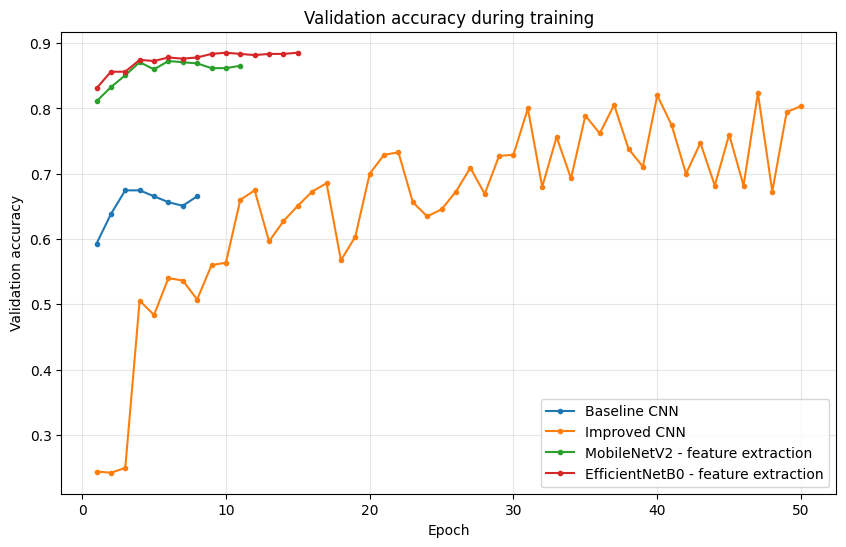

In [29]:
# validation accuracy of every experiment on the same plot
plt.figure(figsize=(10, 6))

for name in ["Baseline CNN", "Improved CNN", "MobileNetV2 - feature extraction", "EfficientNetB0 - feature extraction"]:
    val = histories[name].history["val_accuracy"]
    plt.plot(range(1, len(val) + 1), val, marker="o", markersize=3, label=name)

plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Validation accuracy during training")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 8. Error analysis on the best model

We now look in more detail at the fine-tuned MobileNetV2 : which classes are confused with each other ?

In [30]:
best_model = tl_model

probs  = best_model.predict(test_ds, verbose=0)
y_pred = probs.argmax(axis=1)
y_true = test_labels


print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

              precision    recall  f1-score   support

       daisy      0.914     0.895     0.904        95
   dandelion      0.920     0.933     0.926       135
       roses      0.938     0.781     0.852        96
  sunflowers      0.909     0.952     0.930       105
      tulips      0.840     0.917     0.876       120

    accuracy                          0.900       551
   macro avg      0.904     0.896     0.898       551
weighted avg      0.902     0.900     0.900       551



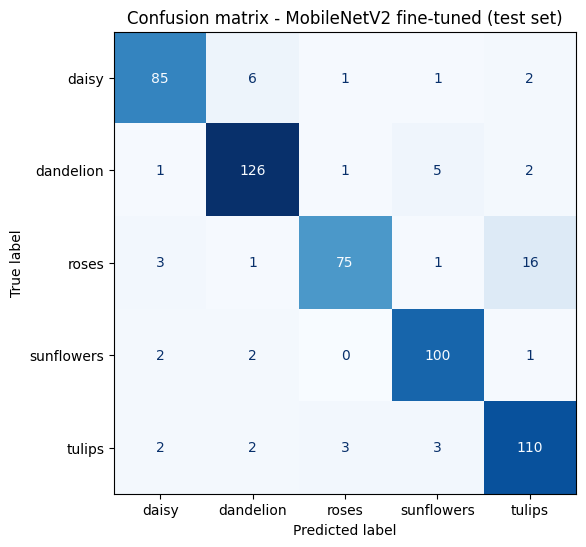

In [31]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion matrix - MobileNetV2 fine-tuned (test set)")
plt.show()

Misclassified : 55 / 551


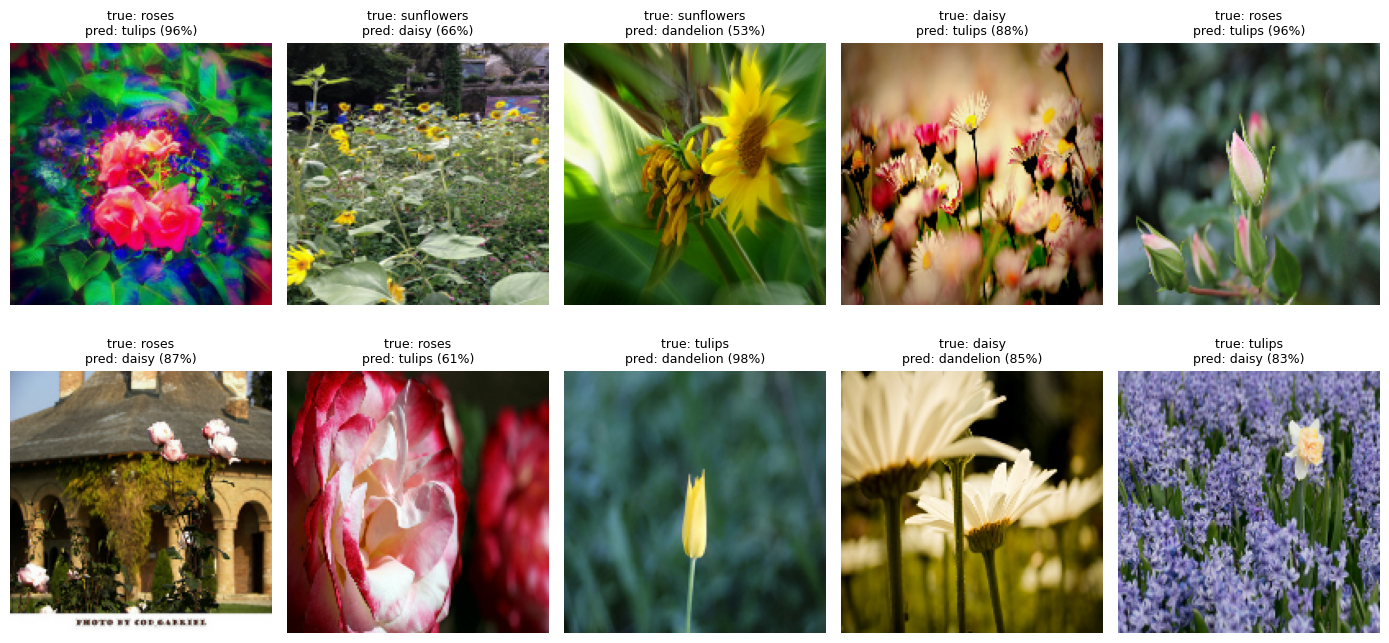

In [32]:
# some of the misclassified images
wrong = np.where(y_pred != y_true)[0]
print("Misclassified :", len(wrong), "/", len(y_true))


plt.figure(figsize=(14, 7))

for i, idx in enumerate(wrong[:10]):
    img, _ = load_image(test_paths[idx], 0)

    plt.subplot(2, 5, i + 1)
    plt.imshow(img.numpy())
    plt.title(f"true: {class_names[y_true[idx]]}\npred: {class_names[y_pred[idx]]} ({probs[idx].max():.0%})", fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

**Observation.** Most errors are between classes that look alike in color or shape, for example roses and tulips (both often red or pink, similar petals). Some errors also come from difficult photos : several flowers of different types in the same image, a flower that is very small in the picture, or close-ups where the shape is not visible.

## 9. Grad-CAM : where does the model look ?

Grad-CAM (Selvaraju et al., 2017) produces a heatmap of the regions of the image that were important for the prediction.

How it works :

1. we take the feature maps of the last convolutional layer (5 x 5 x 1280 for MobileNetV2 at 160x160)
2. we compute the gradient of the score of the predicted class with respect to these feature maps
3. we average the gradient over each map : this gives one weight per feature map (how much it matters for this class)
4. weighted sum of the maps, then ReLU (we only keep the positive influence), then we resize it to the size of the image

In [33]:
def grad_cam(img):
    x = tf.convert_to_tensor(img[None, ...], dtype=tf.float32)
    x = preprocess(x)

    with tf.GradientTape() as tape:
        feature_maps = base_model(x, training=False)       # (1, 5, 5, 1280)
        tape.watch(feature_maps)

        pooled = tl_model.get_layer("gap")(feature_maps)
        preds  = tl_model.get_layer("predictions")(pooled)
        class_idx = tf.argmax(preds[0])
        score = preds[:, class_idx]

    grads = tape.gradient(score, feature_maps)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))         # one weight per feature map

    cam = tf.reduce_sum(feature_maps[0] * weights, axis=-1)
    cam = tf.nn.relu(cam)
    cam = cam / (tf.reduce_max(cam) + 1e-8)

    cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE))[..., 0]
    return cam.numpy(), int(class_idx)

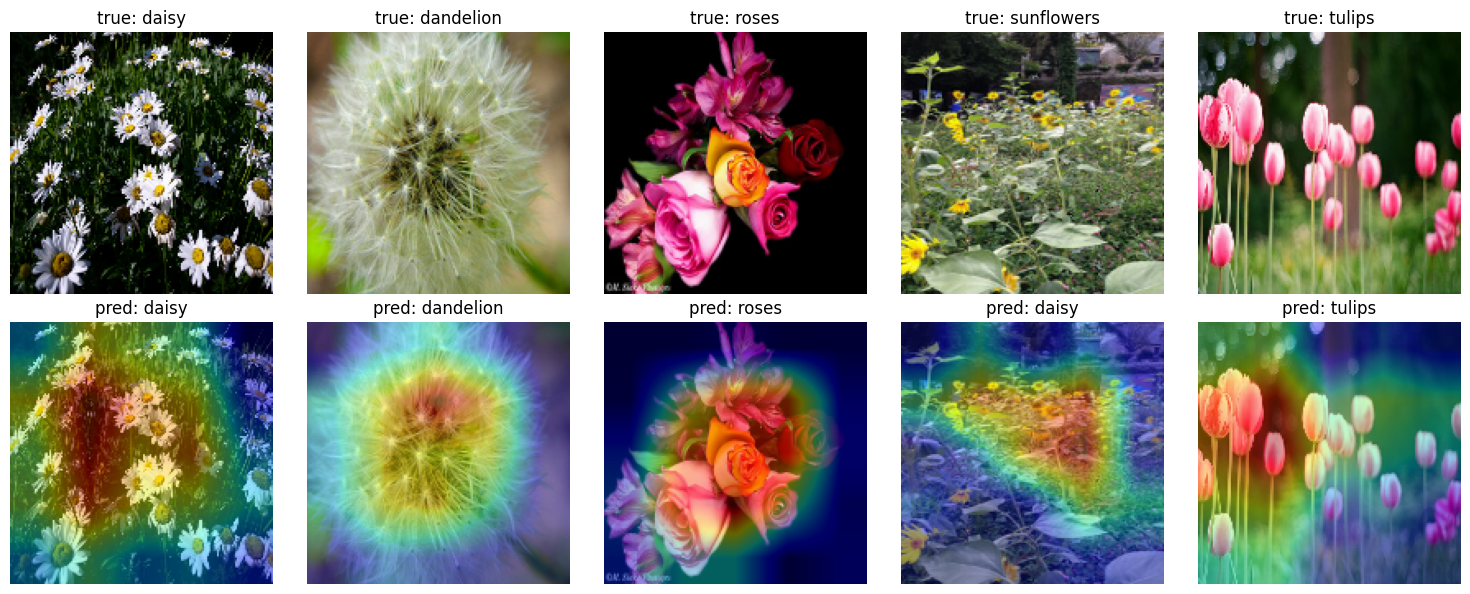

In [34]:
plt.figure(figsize=(15, 6))

for i in range(5):
    idx = np.where(y_true == i)[0][0]         # first test image of each class
    img, _ = load_image(test_paths[idx], 0)
    img = img.numpy()

    heatmap, pred = grad_cam(img.astype("float32"))

    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title(f"true: {class_names[i]}")
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(img)
    plt.imshow(heatmap, cmap="jet", alpha=0.4)
    plt.title(f"pred: {class_names[pred]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

**Observation.** On most images the heatmap is centered on the flower itself (the petals and the heart of the flower) and not on the background, which is reassuring : the model uses the right information. The map is quite coarse because the last feature maps are only 5 x 5.

## 10. Conclusion

* A CNN trained **from scratch** on ~2,500 images overfits quickly. Data augmentation, batch normalization and dropout reduce the overfitting and improve the test accuracy, but the model stays limited by the small amount of data.
* **Transfer learning** gives the biggest improvement : with a frozen MobileNetV2 and only ~6,400 trainable parameters, we get a much better accuracy in a few epochs. The features learned on ImageNet transfer very well to flowers.
* **Fine-tuning** the top layers with a small learning rate adds a few more points.
* EfficientNetB0 gives results in the same range as MobileNetV2 : on this dataset the choice of the backbone matters less than the fact of using a pretrained one.
* The remaining errors are mostly between visually close classes (roses / tulips) or on difficult photos, and Grad-CAM shows the model focuses on the flowers.

**Possible improvements :** a bigger input resolution (224x224), unfreezing more layers, a learning rate schedule, or test-time augmentation.